In [23]:

import os
import random
import json
import pandas as pd
import numpy as np
import cv2
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import matplotlib.pyplot as plt
from collections import Counter
import matplotlib.patches as patches

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Check device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🔧 Using device: {device}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")




🔧 Using device: cuda
   GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [5]:
BASE_DIR = '.'
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")
df_sample_submission = pd.read_csv("sample_submission.csv")

# EDA

Number of training images in COCO: 750
Number of annotations: 1509
Categories: ['Images', 'entete', 'vin']
Annotation counts per category:
  vin: 755
  entete: 754


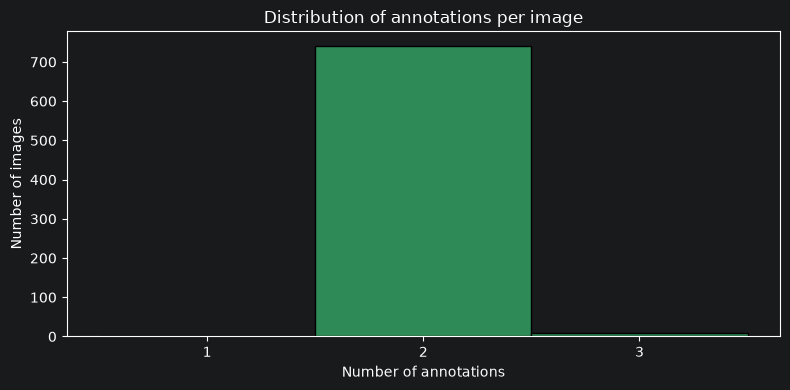

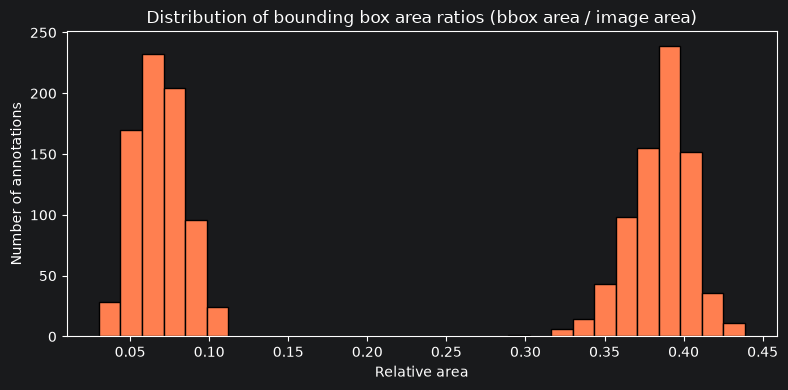

In [24]:
# Load COCO annotations for bounding boxes
annotations_path = os.path.join(BASE_DIR, 'train', '_annotations.coco.json')
with open(annotations_path, 'r', encoding='utf-8') as f:
    coco = json.load(f)

images = coco['images']
annotations = coco['annotations']
categories = coco['categories']

print(f'Number of training images in COCO: {len(images)}')
print(f'Number of annotations: {len(annotations)}')
print('Categories:', [cat['name'] for cat in categories])

category_counts = Counter()
annotations_per_image = Counter()
area_ratios = []
image_dim = {img['id']: (img['width'], img['height']) for img in images}

for ann in annotations:
    category_counts[ann['category_id']] += 1
    annotations_per_image[ann['image_id']] += 1
    bbox = ann['bbox']
    img_w, img_h = image_dim[ann['image_id']]
    area_ratios.append((bbox[2] * bbox[3]) / (img_w * img_h))

id_to_cat = {cat['id']: cat['name'] for cat in categories}
print('Annotation counts per category:')
for cat_id, count in category_counts.items():
    print(f'  {id_to_cat[cat_id]}: {count}')

# Plot distribution of annotations per image
plt.figure(figsize=(8,4))
plt.hist(list(annotations_per_image.values()), bins=range(1, max(annotations_per_image.values()) + 2),
         color='seagreen', edgecolor='black', align='left')
plt.title('Distribution of annotations per image')
plt.xlabel('Number of annotations')
plt.ylabel('Number of images')
plt.xticks(range(1, max(annotations_per_image.values()) + 1))
plt.tight_layout()
plt.show()

# Plot distribution of bounding box area ratios
plt.figure(figsize=(8,4))
plt.hist(area_ratios, bins=30, color='coral', edgecolor='black')
plt.title('Distribution of bounding box area ratios (bbox area / image area)')
plt.xlabel('Relative area')
plt.ylabel('Number of annotations')
plt.tight_layout()
plt.show()

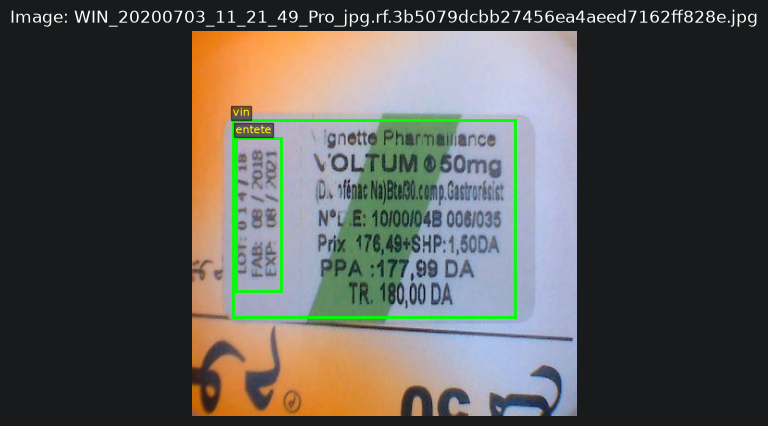

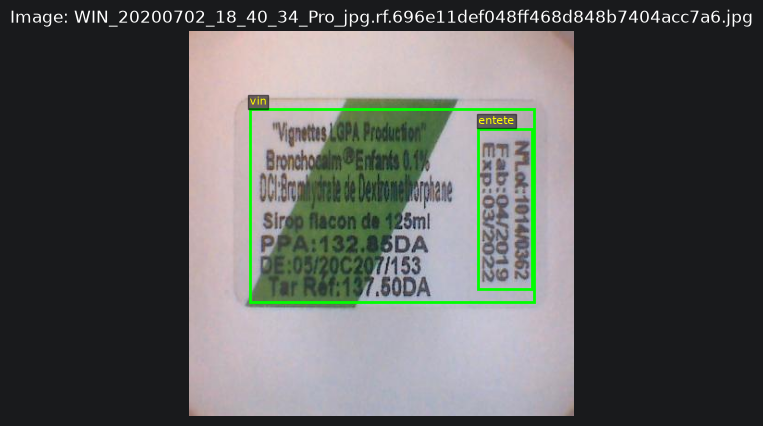

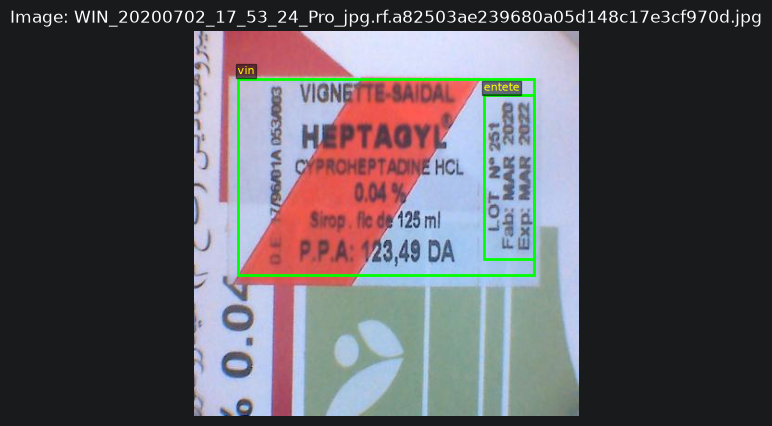

In [13]:
# Visualize random training images with bounding boxes
n_samples = 3
sample_images = random.sample(images, n_samples)

for img_info in sample_images:
    img_id = img_info['id']
    file_name = img_info['file_name']
    img_path = os.path.join(BASE_DIR, 'train', file_name)
    img = Image.open(img_path).convert('RGB')
    fig, ax = plt.subplots(1,1, figsize=(5,5))
    ax.imshow(img)
    for ann in annotations:
        if ann['image_id'] == img_id:
            bbox = ann['bbox']
            rect = patches.Rectangle((bbox[0], bbox[1]), bbox[2], bbox[3],
                                     linewidth=2, edgecolor='lime', facecolor='none')
            ax.add_patch(rect)
            cat_name = id_to_cat[ann['category_id']]
            ax.text(bbox[0], max(bbox[1] - 5, 0), cat_name, color='yellow', fontsize=8,
                    bbox=dict(facecolor='black', alpha=0.5, pad=1))
    ax.set_title(f'Image: {file_name}')
    ax.axis('off')
    plt.show()

8# STARTER

In [17]:
id_column = df_sample_submission.columns[0]
target_column = df_sample_submission.columns[1]

placeholder_text = 'recognized-text'.upper()
predictions = np.full(len(df_test), placeholder_text)

In [18]:
submission_df = pd.DataFrame({
    id_column: df_test[id_column], # Use the ID column from the test data
    target_column: predictions
})

# Crucially, save the file as 'submission.csv' to the working directory.
# The `index=False` argument is essential to prevent pandas from writing row numbers.
submission_df.to_csv('submission.csv', index=False)

print("\nSuccessfully created submission.csv!")
print("Submission Head:")
print(submission_df.head())


Successfully created submission.csv!
Submission Head:
                                     id             text
0  0016f1ad9e7f16aa6dd2b8c9c13cb922.jpg  RECOGNIZED-TEXT
1  005e28f75a93bc4de0e9e11373bdca47.jpg  RECOGNIZED-TEXT
2  007f7b00eb0a66cabcd72007358e3660.jpg  RECOGNIZED-TEXT
3  009a43c2870949af417f769b90ee20cf.jpg  RECOGNIZED-TEXT
4  014d3d8a2ef0d4deb88a83357781745c.jpg  RECOGNIZED-TEXT


# BASELINE PROTOKOL

In [19]:
import argparse
import json
import random
import re
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

TS_RE = re.compile(r"WIN_(\d{8})_(\d{2})_(\d{2})_(\d{2})")

In [26]:

def parse_ts(name):
    """'WIN_20200702_14_56_08_Pro...' -> datetime; None jika pola tidak cocok."""
    m = TS_RE.search(name)
    return datetime.strptime("".join(m.groups()), "%Y%m%d%H%M%S") if m else None


def largest(boxes):
    """Dari beberapa kotak [x, y, w, h], ambil yang terluas (None jika kosong)."""
    return max(boxes, key=lambda b: b[2] * b[3]) if boxes else None


def load_coco(path):
    coco = json.load(open(annotations_path, encoding="utf-8"))
    cat_name = {c["id"]: c["name"] for c in coco["categories"]}  # petakan per NAMA, bukan indeks
    per_img = {}
    for a in coco["annotations"]:
        per_img.setdefault(a["image_id"], {}).setdefault(cat_name[a["category_id"]], []).append(a["bbox"])
    rows = []
    for im in coco["images"]:
        boxes = per_img.get(im["id"], {})
        rows.append(dict(
            image_id=im["id"], file_name=im["file_name"], width=im["width"], height=im["height"],
            ts=parse_ts(im["file_name"]),
            n_entete=len(boxes.get("entete", [])),
            entete=largest(boxes.get("entete", [])), vin=largest(boxes.get("vin", [])),
        ))
    return pd.DataFrame(rows)


def blocked_split(df, block_size=30, val_frac=0.2, seed=42):
    """
    Urutkan menurut waktu, potong jadi blok berurutan, lalu acak PER BLOK.
    Frame yang berdekatan waktunya selalu masuk split yang sama -> mengurangi kebocoran.
    """
    df = df.sort_values(["ts", "file_name"], na_position="first").reset_index(drop=True)
    df["block"] = np.arange(len(df)) // block_size
    blocks = sorted(df["block"].unique())
    val_blocks = set(random.Random(seed).sample(blocks, max(1, round(len(blocks) * val_frac))))
    df["split"] = np.where(df["block"].isin(val_blocks), "val", "train")
    return df


def crop_box(img, box, pad=0.08):
    """Potong kotak [x, y, w, h] dengan padding relatif; jika tegak, putar 90 deg agar horizontal."""
    H, W = img.shape[:2]
    x, y, w, h = box
    x1, y1 = max(0, int(x - pad * w)), max(0, int(y - pad * h))
    x2, y2 = min(W, int(x + w + pad * w)), min(H, int(y + h + pad * h))
    crop = img[y1:y2, x1:x2]
    if crop.shape[0] > crop.shape[1]:
        crop = np.ascontiguousarray(np.rot90(crop))
    return crop


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--coco", required=True)
    ap.add_argument("--images_dir", default=None, help="default: folder file COCO")
    ap.add_argument("--out_dir", required=True)
    ap.add_argument("--block_size", type=int, default=30)
    ap.add_argument("--val_frac", type=float, default=0.2)
    ap.add_argument("--n_gold", type=int, default=80)
    ap.add_argument("--seed", type=int, default=42)
    a = ap.parse_args(argv)

    images_dir = Path(a.images_dir) if a.images_dir else Path(a.coco).parent
    out = Path(a.out_dir)
    (out / "crops").mkdir(parents=True, exist_ok=True)

    df = blocked_split(load_coco(a.coco), a.block_size, a.val_frac, a.seed)

    crop_paths = []
    for r in df.itertuples():
        img = cv2.imread(str(images_dir / r.file_name))
        if img is None or r.entete is None:        # catat, jangan hilang diam-diam
            crop_paths.append("")
            continue
        p = out / "crops" / (Path(r.file_name).stem + ".png")
        cv2.imwrite(str(p), crop_box(img, r.entete))
        crop_paths.append(str(p))
    df["crop_path"] = crop_paths
    df.to_csv(out / "meta.csv", index=False)

    val = df[(df["split"] == "val") & (df["crop_path"] != "")]
    gold = val.sample(min(a.n_gold, len(val)), random_state=a.seed)[["file_name", "crop_path"]]
    gold = gold.rename(columns={"file_name": "id"}).assign(verified_text="")
    gold.to_csv(out / "gold_candidates.csv", index=False)

    print(df.groupby("split").size().to_string())
    print("gambar tanpa entete:", int((df["entete"].isna()).sum()),
          "| gambar dengan >1 entete:", int((df["n_entete"] > 1).sum()),
          "| crop gagal:", int((df["crop_path"] == "").sum()))
    print("gold candidates:", len(gold))

import phase0_prepare as p
p.main(["--coco", "train/_annotations.coco.json", "--out_dir", "phase0"])


split
train    600
val      150
gambar tanpa entete: 0 | gambar dengan >1 entete: 4 | crop gagal: 0
gold candidates: 80
